# Lab 6

You are tasked with evaluating card counting strategies for black jack. In order to do so, you will use object oriented programming to create a playable casino style black jack game where a computer dealer plays against $n$ computer players and possibly one human player. If you don't know the rules of blackjack or card counting, please google it. 

A few requirements:
* The game should utilize multiple 52-card decks. Typically the game is played with 6 decks.
* Players should have chips.
* Dealer's actions are predefined by rules of the game (typically hit on 16). 
* The players should be aware of all shown cards so that they can count cards.
* Each player could have a different strategy.
* The system should allow you to play large numbers of games, study the outcomes, and compare average winnings per hand rate for different strategies.

1. Begin by creating a classes to represent cards and decks. The deck should support more than one 52-card set. The deck should allow you to shuffle and draw cards. Include a "plastic" card, placed randomly in the deck. Later, when the plastic card is dealt, shuffle the cards before the next deal.

In [76]:
import random


# class with 52 cards, one extra plastic card, so 53 total
class Card:
  RANKS = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'J', 'Q', 'K', 'A']
  SUITS = ['Hearts', 'Diamonds', 'Clubs', 'Spades']
  show_suits = True

  def __init__(self, rank, suit, is_plastic=False):
    self.rank = rank
    self.suit = suit
    self.is_plastic = is_plastic

  def get_value(self):
    if self.is_plastic:
      return 0
    if self.rank in ['J', 'Q', 'K']:
      return 10
    if self.rank == 'A':
      return 11
    return int(self.rank)

  def __str__(self):
    if self.is_plastic:
      return 'PLASTIC CUT CARD'
    if Card.show_suits:
      return f'{self.rank} of {self.suit}'
    return f'{self.rank}'

  def __repr__(self):
    return self.__str__()


# class of decks of cards. can support more than one 52-set of cards. able to shuffle and draw cards. shuffles when plastic card is drawn before next deal
class Deck:

  def __init__(self, num_decks=6):
    self.num_decks = num_decks
    self.cards = []
    self.needs_shuffle = False
    # automatically build and shuffle the shoe when Deck is created
    self.shuffle_deck()

  def create_deck(self):
    self.cards = []
    for _ in range(self.num_decks):
      for suit in Card.SUITS:
        for rank in Card.RANKS:
          self.cards.append(Card(rank, suit))

  def shuffle_deck(self):
    self.create_deck()
    random.shuffle(self.cards)

    # insert plastic card at a random position in shoe, of course not top or bottom
    plastic_card = Card('PLASTIC', 'PLASTIC', is_plastic=True)
    insert_position = random.randint(1, len(self.cards) - 1)
    self.cards.insert(insert_position, plastic_card)

    self.needs_shuffle = False

  def draw_card(self):
    # if plastic card is drawn flags needs_shuffle for next deal and draws the next real card

    if len(self.cards) == 0:
      self.shuffle_deck()

    drawn_card = self.cards.pop()

    if drawn_card.is_plastic:
      self.needs_shuffle = True
      # draw the next card so a player never receives the plastic card
      return self.draw_card()

    return drawn_card

In [77]:
# test

random.seed(8)  # fixed seed for reproducible test output
deck = Deck(num_decks=6)
print(
    f'Created {deck.num_decks}-deck shoe with {len(deck.cards)} total'
    f' cards ({len(deck.cards)-1} regular + 1 plastic cut card)\n'
)

# preview the first 5 drawn cards and their values
print('First 5 cards drawn:')
for i in range(1, 6):
  sample_card = deck.draw_card()
  print(f'  Card {i}: {sample_card} (Value: {sample_card.get_value()})')
print()

# reset shoe and simulate dealing 80 four-card rounds (320 cards total)
deck.shuffle_deck()
total_cards_dealt = 0
plastic_triggered_count = 0

for round_num in range(1, 81):
  # check before each new deal if the plastic card was drawn in the previous round
  if deck.needs_shuffle:
    print(
        f'[Before Round {round_num}] Reshuffling shoe because plastic card'
        ' was reached in the previous round'
    )
    deck.shuffle_deck()
    print(f'  -> Shoe restored to {len(deck.cards)} cards\n')

  # simulate dealing 4 cards in this round
  round_cards = []
  for _ in range(4):
    was_flagged = deck.needs_shuffle
    card = deck.draw_card()
    round_cards.append(card)
    total_cards_dealt += 1

    # verify that the plastic card was never dealt into a hand
    assert not card.is_plastic, 'Error: Plastic card was dealt to a player!'
    assert 2 <= card.get_value() <= 11, f'Error: Invalid card value on {card}'

    if not was_flagged and deck.needs_shuffle:
      plastic_triggered_count += 1
      print(
          f'[Round {round_num}] Plastic cut card encountered mid-round!'
          f' Dealt replacement card: {card}'
      )
      print(
          f'  -> Cards remaining in shoe: {len(deck.cards)} |'
          f' needs_shuffle: {deck.needs_shuffle}'
      )

print(
    f'\nTest complete: {total_cards_dealt} real cards dealt across 80 rounds,'
    f' plastic cut card triggered {plastic_triggered_count} time(s), and 0'
    ' plastic cards ended up in a hand'
)

Created 6-deck shoe with 313 total cards (312 regular + 1 plastic cut card)

First 5 cards drawn:
  Card 1: A of Hearts (Value: 11)
  Card 2: 9 of Clubs (Value: 9)
  Card 3: Q of Clubs (Value: 10)
  Card 4: A of Hearts (Value: 11)
  Card 5: 9 of Spades (Value: 9)

[Round 61] Plastic cut card encountered mid-round! Dealt replacement card: 6 of Clubs
  -> Cards remaining in shoe: 70 | needs_shuffle: True
[Before Round 62] Reshuffling shoe because plastic card was reached in the previous round
  -> Shoe restored to 313 cards


Test complete: 320 real cards dealt across 80 rounds, plastic cut card triggered 1 time(s), and 0 plastic cards ended up in a hand


2. Now design your game on a UML diagram. You may want to create classes to represent, players, a hand, and/or the game. As you work through the lab, update your UML diagram. At the end of the lab, submit your diagram (as pdf file) along with your notebook. 

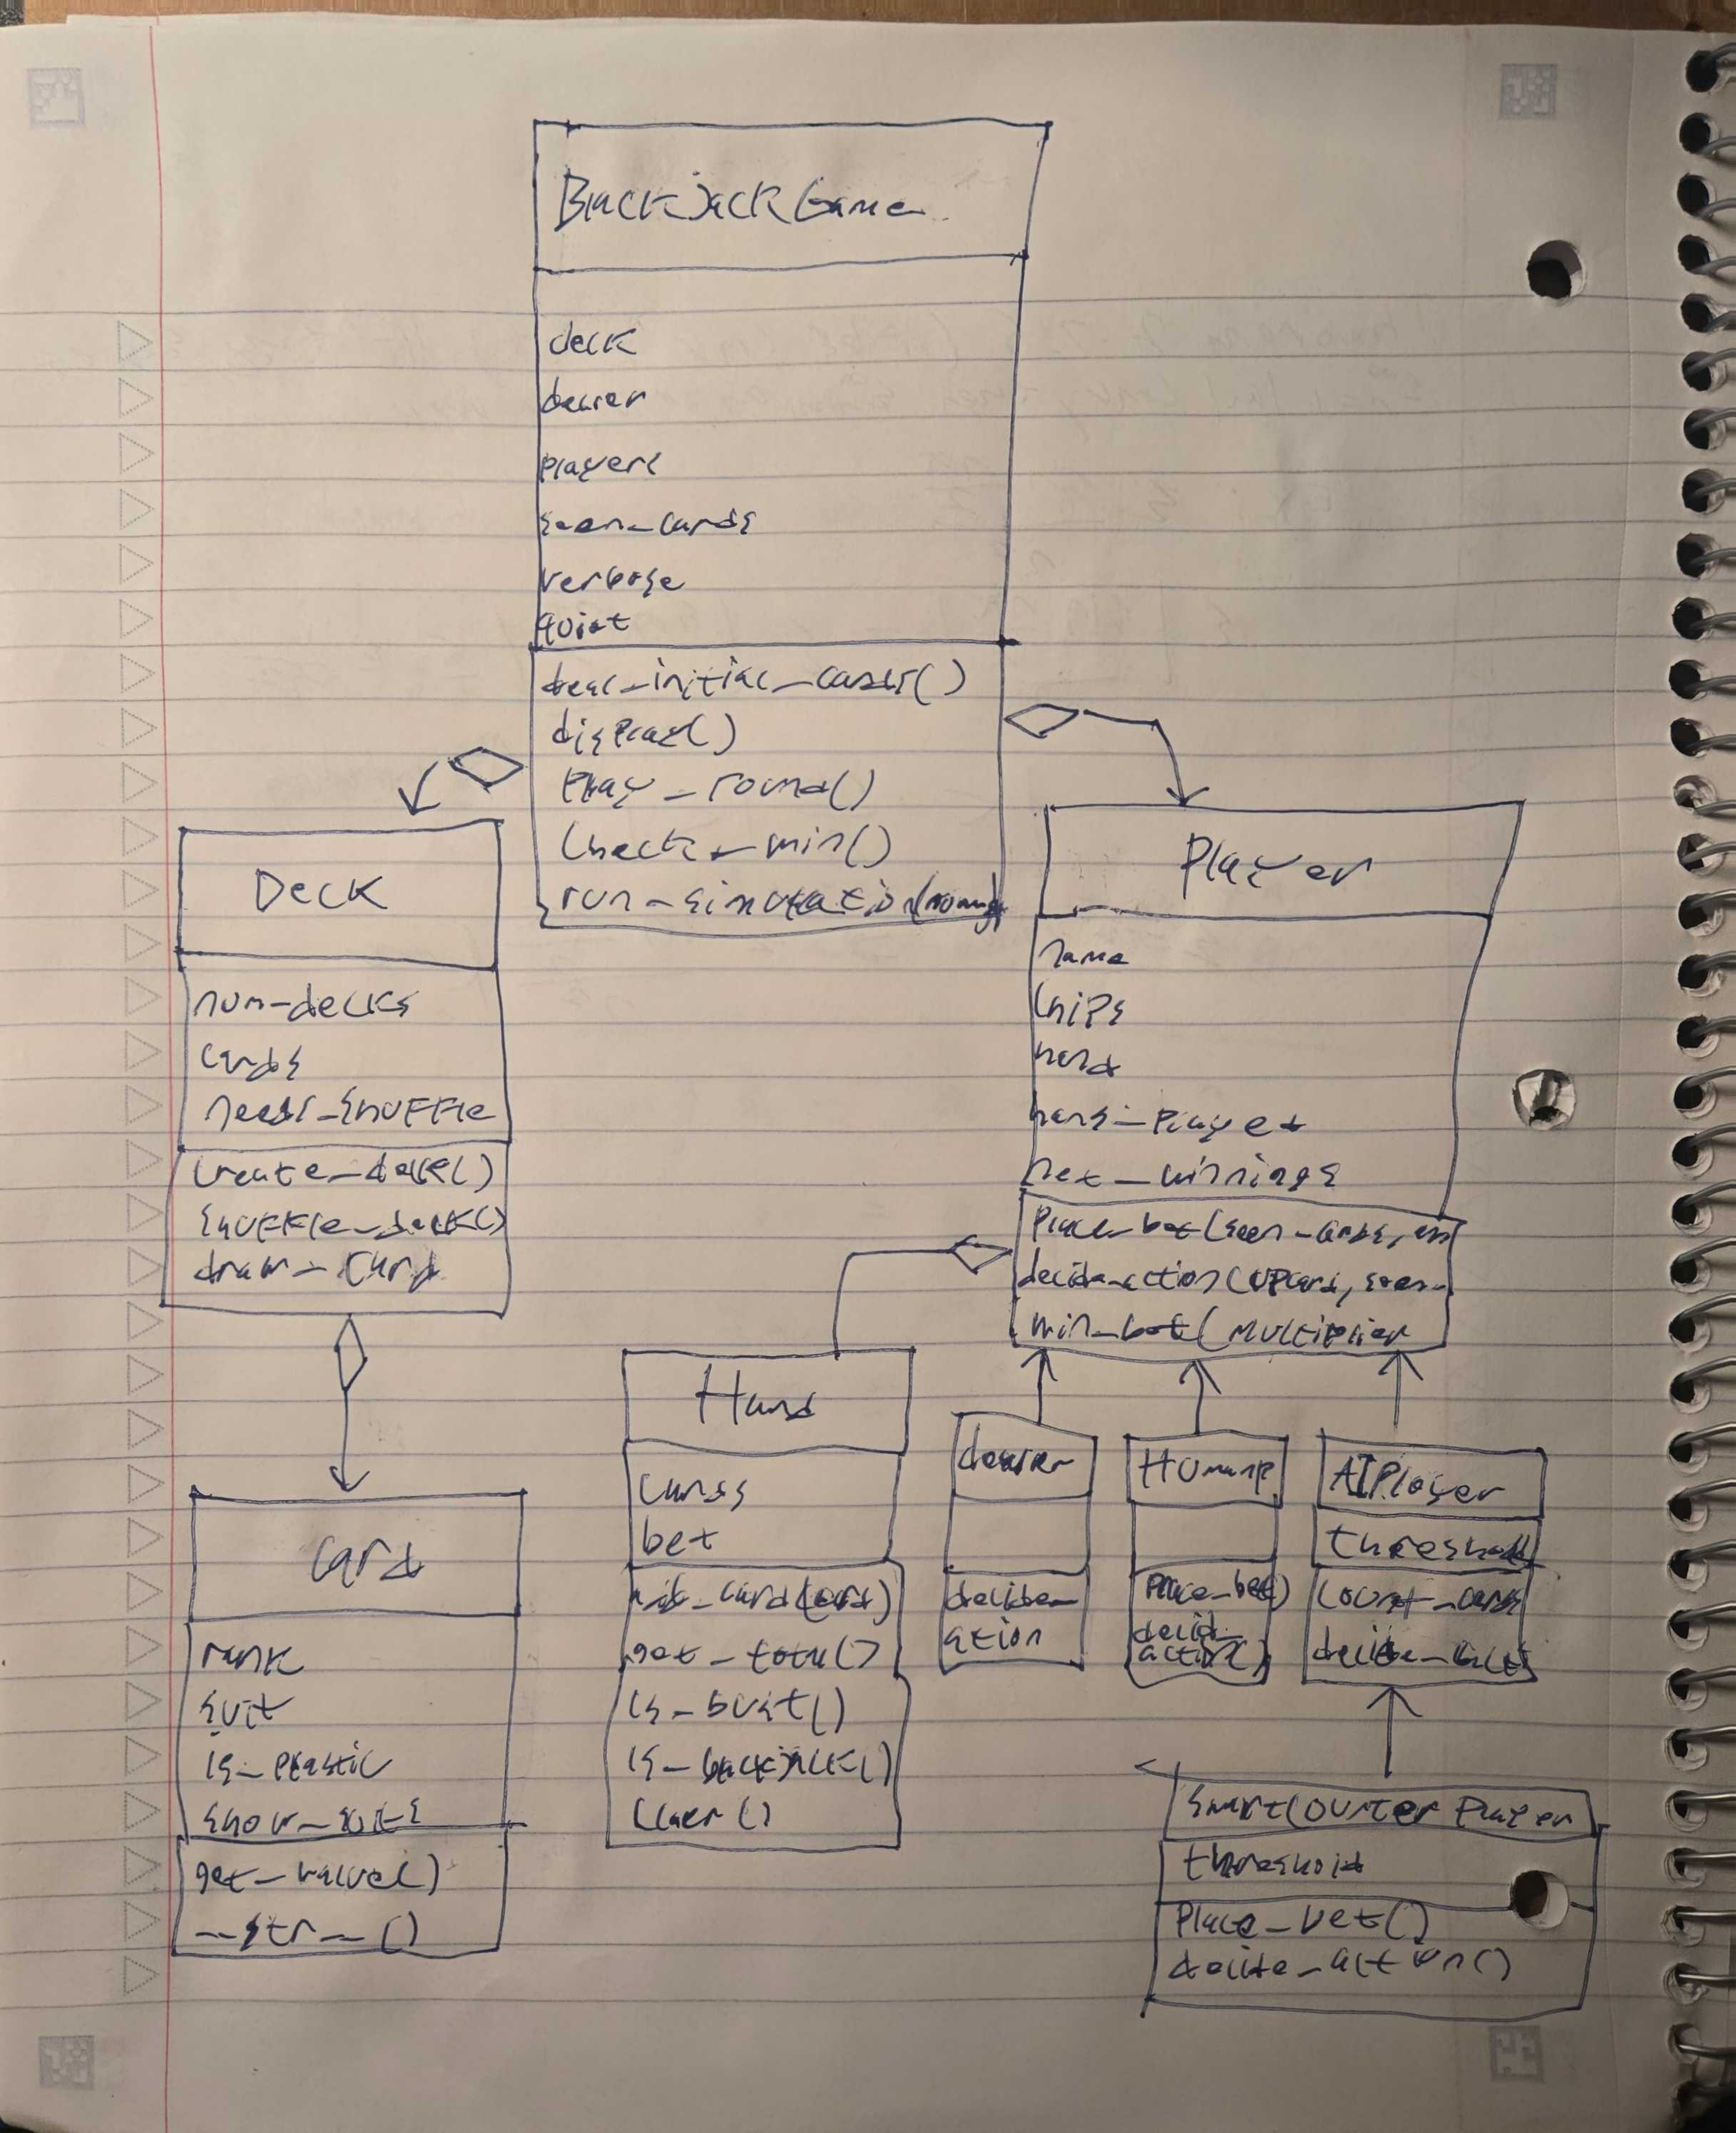

3. Begin with implementing the skeleton (ie define data members and methods/functions, but do not code the logic) of the classes in your UML diagram.

In [78]:
class Hand:

  def __init__(self):
    self.cards = []
    self.bet = 0

  def add_card(self, card):
    pass

  def get_total(self):
    pass

  def is_bust(self):
    pass

  def is_blackjack(self):
    pass

  def clear(self):
    pass


class Player:

  def __init__(self, name='Player', chips=1000):
    self.name = name
    self.chips = chips
    self.hand = Hand()
    self.hands_played = 0
    self.net_winnings = 0

  def place_bet(self, seen_cards):
    pass

  def decide_action(self, dealer_upcard, seen_cards):
    pass

  def win_bet(self, multiplier):
    pass


class Dealer(Player):

  def __init__(self):
    super().__init__(name='Dealer', chips=0)

  def decide_action(self, dealer_upcard, seen_cards):
    pass


class HumanPlayer(Player):

  def __init__(self, name='Human', chips=1000):
    super().__init__(name=name, chips=chips)

  def place_bet(self, seen_cards):
    pass

  def decide_action(self, dealer_upcard, seen_cards):
    pass


class AIPlayer(Player):

  def __init__(self, name='AI', chips=1000, strategy_type='basic'):
    super().__init__(name=name, chips=chips)
    self.strategy_type = strategy_type

  def place_bet(self, seen_cards):
    pass

  def decide_action(self, dealer_upcard, seen_cards):
    pass

  def count_cards(self, seen_cards):
    pass


class BlackjackGame:

  def __init__(self, players=None, num_decks=6):
    self.deck = Deck(num_decks=num_decks)
    self.dealer = Dealer()
    self.players = players if players is not None else []
    self.seen_cards = []

  def deal_initial_cards(self):
    pass

  def play_round(self):
    pass

  def check_win(self):
    pass

  def display(self):
    pass

  def run_simulation(self, num_games):
    pass

4. Complete the implementation by coding the logic of all functions. For now, just implement the dealer player and human player.

In [112]:
class Hand:

  def __init__(self):
    self.cards = []
    self.bet = 0

  # adds dealt card to hand
  def add_card(self, card):
    self.cards.append(card)

  # calculate hand total value. if ace causes bust, reduce to 1 from 11
  def get_total(self):
    total = sum(card.get_value() for card in self.cards)
    aces = sum(1 for card in self.cards if card.rank == 'A')
    while total > 21 and aces > 0:
      total -= 10
      aces -= 1
    return total

  # returns true if hand over 21
  def is_bust(self):
    return self.get_total() > 21

  # returns true if hand is a natural 2 card 21
  def is_blackjack(self):
    return len(self.cards) == 2 and self.get_total() == 21

  # resets hand and bet before new round
  def clear(self):
    self.cards = []
    self.bet = 0

  def __str__(self):
    cards_str = ', '.join(str(card) for card in self.cards)
    return f'[{cards_str}] (Total: {self.get_total()})'


class Player:

  def __init__(self, name='Player', chips=1000):
    self.name = name
    self.chips = chips
    self.hand = Hand()
    self.hands_played = 0
    self.net_winnings = 0

  # reduces chips by bet amount and attaches to hand
  def place_bet(self, seen_cards, amount=10):
    bet = min(amount, self.chips)
    self.chips -= bet
    self.net_winnings -= bet
    self.hand.bet = bet
    return bet

  # default player actions (hit or stand)
  def decide_action(self, dealer_upcard, seen_cards):
    return 'stand'

  # pays out chips based on multiplier (0=loss, 1=push, 2=win, 2.5=blackjack)
  def win_bet(self, multiplier):
    payout = int(self.hand.bet * multiplier)
    self.chips += payout
    self.net_winnings += payout


class Dealer(Player):

  def __init__(self, name='Dealer', chips=0):
    super().__init__(name=name, chips=chips)

  def decide_action(self, dealer_upcard=None, seen_cards=None):
    # dealer must hit on 16 or under, and stand on 17 or over
    if self.hand.get_total() <= 16:
      return 'hit'
    return 'stand'


class HumanPlayer(Player):

  def __init__(self, name='Human', chips=1000):
    super().__init__(name=name, chips=chips)

  def place_bet(self, seen_cards):
    # prompts the human player to enter a valid chip bet
    while True:
      try:
        raw = input(
            f'\n{self.name}, you have {self.chips} chips. Enter your bet: '
        ).strip()
        bet = int(raw)
        if 1 <= bet <= self.chips:
          self.chips -= bet
          self.net_winnings -= bet
          self.hand.bet = bet
          return bet
        print(f'Please enter a bet between 1 and {self.chips}.')
      except ValueError:
        print('Invalid input. Please enter a whole number.')

  # prompts human player to hit or stand
  def decide_action(self, dealer_upcard, seen_cards):
    while True:
      choice = (
          input(
              f'{self.name} ({self.hand}) vs Dealer showing [{dealer_upcard}]'
              ' -> (h)it or (s)tand? '
          )
          .strip()
          .lower()
      )
      if choice in ['h', 'hit']:
        return 'hit'
      if choice in ['s', 'stand']:
        return 'stand'
      print("Invalid choice. Please type 'h' to hit or 's' to stand.")


class BlackjackGame:

  def __init__(
      self,
      players=None,
      num_decks=6,
      verbose=True,
      show_suits=True,
      quiet=False,
  ):
    self.deck = Deck(num_decks=num_decks)
    self.dealer = Dealer()
    self.players = players if players is not None else [HumanPlayer()]
    self.seen_cards = []
    Card.show_suits = show_suits
    self.verbose = verbose
    self.quiet = quiet

  # draws a card from the shoe and adds it to "seen_cards" if faceup
  def draw_table_card(self, reveal=True):
    card = self.deck.draw_card()
    if reveal:
      self.seen_cards.append(card)
    return card

  # deals 2 cards to each active player and the dealer (dealer's 2nd card is facedown)
  def deal_initial_cards(self):
    for round_idx in range(2):
      for player in self.players:
        if player.hand.bet > 0:
          player.hand.add_card(self.draw_table_card(reveal=True))
      # dealer's first card is faceup. second card is facedown
      is_upcard = round_idx == 0
      self.dealer.hand.add_card(self.draw_table_card(reveal=is_upcard))

  # prints the current table state
  def display(self, hide_dealer_hole_card=True):
    if self.quiet:
      return
    if self.verbose:
      print('\n--Current Table--')
      if hide_dealer_hole_card and len(self.dealer.hand.cards) >= 2:
        upcard = self.dealer.hand.cards[0]
        print(f'Dealer: [{upcard}, HIDDEN] (Showing: {upcard.get_value()})')
      else:
        print(f'Dealer: {self.dealer.hand}')

      for player in self.players:
        if player.hand.bet > 0:
          print(
              f'{player.name}: {player.hand} | Bet: {player.hand.bet} | Chips'
              f' remaining: {player.chips}'
          )
      print(f'Seen cards in shoe so far: {len(self.seen_cards)}')
    else:
      print()
      if hide_dealer_hole_card and len(self.dealer.hand.cards) >= 2:
        upcard = self.dealer.hand.cards[0]
        print(f'Dealer shows {upcard}, hidden, total: {upcard.get_value()}')
      else:
        print(f'Dealer total: {self.dealer.hand.get_total()}')
      for player in self.players:
        if player.hand.bet > 0:
          print(f'{player.name} total: {player.hand.get_total()}')

  # executes one complete round of Blackjack
  def play_round(self):
    # 1. reshuffle before the deal if the plastic card was drawn last round
    if self.deck.needs_shuffle:
      if not self.quiet:
        if self.verbose:
          print('\n[Shoe] Plastic card was reached! Reshuffling shoe...')
        else:
          print('\n[Reshuffling shoe]')
      self.deck.shuffle_deck()
      self.seen_cards.clear()

    # 2. clear previous hands and collect bets from players who have chips
    self.dealer.hand.clear()
    active_players = []
    for player in self.players:
      player.hand.clear()
      if player.chips > 0:
        player.place_bet(self.seen_cards)
        active_players.append(player)
      elif not self.quiet and self.verbose:
        print(f'{player.name} is out of chips and sits out this round.')

    if not active_players:
      if not self.quiet and self.verbose:
        print('No active players with chips remaining.')
      return

    # 3. deal initial 2 cards and display the opening table
    self.deal_initial_cards()
    self.display(hide_dealer_hole_card=True)

    dealer_upcard = self.dealer.hand.cards[0]

    # 4. each player takes their turn (unless dealer already has a natural Blackjack)
    if not self.dealer.hand.is_blackjack():
      for player in active_players:
        if player.hand.is_blackjack():
          if not self.quiet:
            if self.verbose:
              print(f'{player.name} has a natural Blackjack!')
            else:
              print(f'{player.name} blackjack (21)')
          continue

        while not player.hand.is_bust():
          action = player.decide_action(dealer_upcard, self.seen_cards)
          if action == 'hit':
            new_card = self.draw_table_card(reveal=True)
            player.hand.add_card(new_card)
            if not self.quiet:
              if self.verbose:
                print(
                    f'  -> {player.name} hits and draws {new_card}. Hand:'
                    f' {player.hand}'
                )
              else:
                print(
                    f'{player.name} draws {new_card}, total:'
                    f' {player.hand.get_total()}'
                )
            if player.hand.is_bust() and not self.quiet:
              if self.verbose:
                print(
                    f'  -> {player.name} busts with {player.hand.get_total()}!'
                )
              else:
                print(f'{player.name} busts')
          else:
            if not self.quiet:
              if self.verbose:
                print(
                    f'  -> {player.name} stands at {player.hand.get_total()}.'
                )
              else:
                print(f'{player.name} stands')
            break

    # 5. reveal dealer's hole card so card counters can track it
    if len(self.dealer.hand.cards) >= 2:
      hole_card = self.dealer.hand.cards[1]
      self.seen_cards.append(hole_card)
      if not self.quiet:
        if self.verbose:
          print(
              f'\nDealer reveals hole card: {hole_card} -> {self.dealer.hand}'
          )
        else:
          print(
              f'Dealer shows {hole_card}, new total:'
              f' {self.dealer.hand.get_total()}'
          )

    # dealer plays only if at least one player is still in the hand
    players_needing_dealer = [
        p
        for p in active_players
        if not p.hand.is_bust() and not p.hand.is_blackjack()
    ]
    if players_needing_dealer and not self.dealer.hand.is_blackjack():
      while not self.dealer.hand.is_bust():
        action = self.dealer.decide_action(dealer_upcard, self.seen_cards)
        if action == 'hit':
          new_card = self.draw_table_card(reveal=True)
          self.dealer.hand.add_card(new_card)
          if not self.quiet:
            if self.verbose:
              print(
                  f'  -> Dealer hits and draws {new_card}. Hand:'
                  f' {self.dealer.hand}'
              )
            else:
              print(
                  f'Dealer draws {new_card}, total:'
                  f' {self.dealer.hand.get_total()}'
              )
          if self.dealer.hand.is_bust() and not self.quiet:
            if self.verbose:
              print(f'  -> Dealer busts with {self.dealer.hand.get_total()}!')
            else:
              print('Dealer busts')
        else:
          if not self.quiet:
            if self.verbose:
              print(f'  -> Dealer stands at {self.dealer.hand.get_total()}.')
            else:
              print('Dealer stands')
          break

    # 6. settle bets and record statistics
    self.check_win()

  # compares each player's hand against the dealer's and settles bets
  def check_win(self):
    dealer_total = self.dealer.hand.get_total()
    dealer_bust = self.dealer.hand.is_bust()
    dealer_bj = self.dealer.hand.is_blackjack()

    if not self.quiet and self.verbose:
      print('\n--Round Results--')

    for player in self.players:
      if player.hand.bet == 0:
        continue

      player.hands_played += 1
      player_total = player.hand.get_total()
      player_bust = player.hand.is_bust()
      player_bj = player.hand.is_blackjack()

      if player_bust:
        player.win_bet(0.0)
        outcome = f'LOST {player.hand.bet} chips (Busted)'
      elif player_bj and dealer_bj:
        player.win_bet(1.0)
        outcome = 'PUSH (Both have Blackjack)'
      elif player_bj:
        player.win_bet(2.5)  # 3:2 payout on natural Blackjack
        profit = int(player.hand.bet * 1.5)
        outcome = f'BLACKJACK! Won +{profit} chips (3:2 payout)'
      elif dealer_bj:
        player.win_bet(0.0)
        outcome = f'LOST {player.hand.bet} chips (Dealer Blackjack)'
      elif dealer_bust or player_total > dealer_total:
        player.win_bet(2.0)
        outcome = (
            f'WON +{player.hand.bet} chips ({player_total} vs {dealer_total})'
        )
      elif player_total == dealer_total:
        player.win_bet(1.0)
        outcome = f'PUSH at {player_total}'
      else:
        player.win_bet(0.0)
        outcome = (
            f'LOST {player.hand.bet} chips ({player_total} vs {dealer_total})'
        )

      if not self.quiet:
        if self.verbose:
          print(
              f'{player.name}: {outcome} | Chips: {player.chips} | Net:'
              f' {player.net_winnings:+d}'
          )
        else:
          print(f'{player.name}: {outcome} (Chips: {player.chips})')

  # runs multiple rounds of Blackjack and returns summary statistics for each player
  def run_simulation(self, num_games):
    for _ in range(num_games):
      self.play_round()

    stats = {}
    for player in self.players:
      avg_rate = (
          player.net_winnings / player.hands_played
          if player.hands_played > 0
          else 0.0
      )
      stats[player.name] = {
          'hands_played': player.hands_played,
          'final_chips': player.chips,
          'net_winnings': player.net_winnings,
          'avg_winnings_per_hand': round(avg_rate, 4),
      }
    return stats

In [93]:
# human test

me = HumanPlayer(name='human', chips=1000)
interactive_game = BlackjackGame(players=[me], num_decks=6, verbose=False, show_suits=False)

while me.chips > 0:
  interactive_game.play_round()

  if me.chips <= 0:
    print('\nYou are out of chips! Game over.')
    break

  keep_playing = input('\nPlay another hand? (y/n): ').strip().lower()
  if keep_playing not in ['y', 'yes']:
    break

print(
    f'\nFinal Stats -> Hands played: {me.hands_played} | Final chips:'
    f' {me.chips} | Net winnings: {me.net_winnings:+d}'
)


Dealer shows 4, hidden, total: 4
human total: 13
human draws 5, total: 18
human stands
Dealer shows 3, new total: 7
Dealer draws 10, total: 17
Dealer stands
human: WON +760 chips (18 vs 17) (Chips: 1760)

Final Stats -> Hands played: 1 | Final chips: 1760 | Net winnings: +760


5.  Test. Demonstrate game play. For example, create a game of several dealer players and show that the game is functional through several rounds.

In [105]:
# simulated test

random.seed(8)

dealer_players = [
    Dealer(name='DealerPlayer 1', chips=1000),
    Dealer(name='DealerPlayer 2', chips=1000),
    Dealer(name='DealerPlayer 3', chips=1000),
]

game_step5 = BlackjackGame(players=dealer_players, num_decks=6, verbose=True, show_suits=False)
stats_step5 = game_step5.run_simulation(num_games=5)

print('\n--Summary After 5 Rounds--')
for player_name, player_stats in stats_step5.items():
  print(f'{player_name}: {player_stats}')



--Current Table--
Dealer: [A, HIDDEN] (Showing: 11)
DealerPlayer 1: [A, 9] (Total: 20) | Bet: 10 | Chips remaining: 990
DealerPlayer 2: [9, J] (Total: 19) | Bet: 10 | Chips remaining: 990
DealerPlayer 3: [Q, 6] (Total: 16) | Bet: 10 | Chips remaining: 990
Seen cards in shoe so far: 7
  -> DealerPlayer 1 stands at 20.
  -> DealerPlayer 2 stands at 19.
  -> DealerPlayer 3 hits and draws J. Hand: [Q, 6, J] (Total: 26)
  -> DealerPlayer 3 busts with 26!

Dealer reveals hole card: 7 -> [A, 7] (Total: 18)
  -> Dealer stands at 18.

--Round Results--
DealerPlayer 1: WON +10 chips (20 vs 18) | Chips: 1010 | Net: +10
DealerPlayer 2: WON +10 chips (19 vs 18) | Chips: 1010 | Net: +10
DealerPlayer 3: LOST 10 chips (Busted) | Chips: 990 | Net: -10

--Current Table--
Dealer: [4, HIDDEN] (Showing: 4)
DealerPlayer 1: [A, 3] (Total: 14) | Bet: 10 | Chips remaining: 1000
DealerPlayer 2: [5, 4] (Total: 9) | Bet: 10 | Chips remaining: 1000
DealerPlayer 3: [Q, K] (Total: 20) | Bet: 10 | Chips remaining: 9

6. Implement a new player with the following strategy:

    * Assign each card a value: 
        * Cards 2 to 6 are +1 
        * Cards 7 to 9 are 0 
        * Cards 10 through Ace are -1
    * Compute the sum of the values for all cards seen so far.
    * Hit if sum is very negative, stay if sum is very positive. Select a threshold for hit/stay, e.g. 0 or -2.  

In [106]:
class AIPlayer(Player):

  def __init__(self, name='CardCounter', chips=1000, threshold=-2):
    super().__init__(name=name, chips=chips)
    self.threshold = threshold

  # assign +1 to 2-6, 0 to 7-9, and -1 to 10-Ace for all seen cards
  def count_cards(self, seen_cards):
    count = 0
    for card in seen_cards:
      if card.rank in ['2', '3', '4', '5', '6']:
        count += 1
      elif card.rank in ['7', '8', '9']:
        count += 0
      elif card.rank in ['10', 'J', 'Q', 'K', 'A']:
        count -= 1
    return count

  # hit if running count is <= threshold (negative), stand if > threshold (positive)
  def decide_action(self, dealer_upcard, seen_cards):
    running_count = self.count_cards(seen_cards)
    if running_count <= self.threshold:
      return 'hit'
    return 'stand'


# quick test of AIPlayer over 3 rounds with threshold = -2
random.seed(8)
counter_player = AIPlayer(
    name='Counter (threshold=-2)', chips=1000, threshold=-2
)
game_step6 = BlackjackGame(players=[counter_player], num_decks=6, verbose=True, show_suits=False)
stats_step6 = game_step6.run_simulation(num_games=3)

print('\n--Step 6 Card Counter Demo Summary--')
for player_name, player_stats in stats_step6.items():
  print(f'{player_name}: {player_stats}')


--Current Table--
Dealer: [9, HIDDEN] (Showing: 9)
Counter (threshold=-2): [A, Q] (Total: 21) | Bet: 10 | Chips remaining: 990
Seen cards in shoe so far: 3
Counter (threshold=-2) has a natural Blackjack!

Dealer reveals hole card: A -> [9, A] (Total: 20)

--Round Results--
Counter (threshold=-2): BLACKJACK! Won +15 chips (3:2 payout) | Chips: 1015 | Net: +15

--Current Table--
Dealer: [J, HIDDEN] (Showing: 10)
Counter (threshold=-2): [9, 6] (Total: 15) | Bet: 10 | Chips remaining: 1005
Seen cards in shoe so far: 7
  -> Counter (threshold=-2) hits and draws J. Hand: [9, 6, J] (Total: 25)
  -> Counter (threshold=-2) busts with 25!

Dealer reveals hole card: 7 -> [J, 7] (Total: 17)

--Round Results--
Counter (threshold=-2): LOST 10 chips (Busted) | Chips: 1005 | Net: +5

--Current Table--
Dealer: [5, HIDDEN] (Showing: 5)
Counter (threshold=-2): [A, Q] (Total: 21) | Bet: 10 | Chips remaining: 995
Seen cards in shoe so far: 12
Counter (threshold=-2) has a natural Blackjack!

Dealer reveals

7. Create a test scenario where one player, using the above strategy, is playing with a dealer and 3 other players that follow the dealer's strategy. Each player starts with same number of chips. Play 50 rounds (or until the strategy player is out of money). Compute the strategy player's winnings. You may remove unnecessary printouts from your code (perhaps implement a verbose/quiet mode) to reduce the output.

In [107]:
random.seed(8)
starting_chips = 1000

strategy_player = AIPlayer(
    name='StrategyPlayer', chips=starting_chips, threshold=-2
)
table_players = [
    strategy_player,
    Dealer(name='DealerPlayer 1', chips=starting_chips),
    Dealer(name='DealerPlayer 2', chips=starting_chips),
    Dealer(name='DealerPlayer 3', chips=starting_chips),
]

game = BlackjackGame(
    players=table_players,
    num_decks=6,
    verbose=False,
    show_suits=False,
    quiet=True,
)

for round_num in range(50):
  if strategy_player.chips <= 0:
    print(f'\nStrategyPlayer ran out of chips after {round_num} rounds!')
    break
  game.play_round()

print('\n--Final Results (50 Rounds)--')
for p in table_players:
  avg_hand = p.net_winnings / p.hands_played if p.hands_played > 0 else 0.0
  print(
      f'{p.name}: Hands={p.hands_played} | Final Chips={p.chips} | Net'
      f' Winnings={p.net_winnings:+d} | Avg/Round={avg_hand:+.2f}'
  )


--Final Results (50 Rounds)--
StrategyPlayer: Hands=50 | Final Chips=860 | Net Winnings=-140 | Avg/Round=-2.80
DealerPlayer 1: Hands=50 | Final Chips=880 | Net Winnings=-120 | Avg/Round=-2.40
DealerPlayer 2: Hands=50 | Final Chips=935 | Net Winnings=-65 | Avg/Round=-1.30
DealerPlayer 3: Hands=50 | Final Chips=970 | Net Winnings=-30 | Avg/Round=-0.60


8. Create a loop that runs 100 games of 50 rounds, as setup in previous question, and store the strategy player's chips at the end of the game (aka "winnings") in a list. Histogram the winnings. What is the average winnings per round? What is the standard deviation. What is the probability of net winning or losing after 50 rounds?


--100 Games of 50 Rounds Summary (threshold = -2)--
Average Final Chips:        793.70 (Started with 1000)
Std Dev of Final Chips:     87.22
Average Winnings per Round: -4.1260 chips/round
Std Dev per Round:          1.7443 chips/round
Probability of Net Winning: 1.00%
Probability of Net Losing:  99.00%
Probability of Break-Even:  0.00%


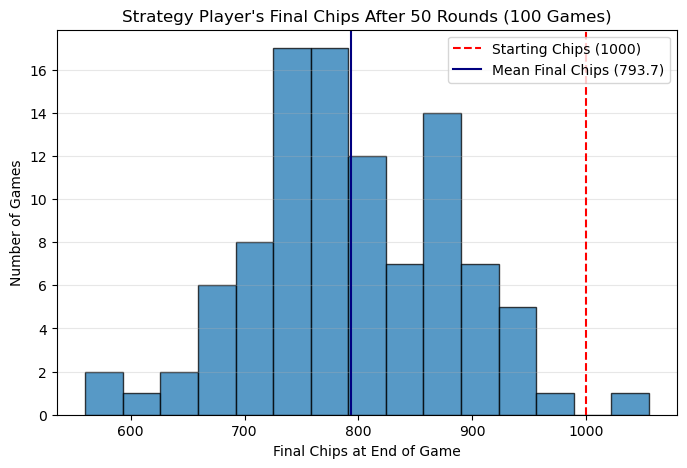

In [ ]:
# avg winnings per round is about -4.13 chips with std dev 1.74, and win probability is 1%

import statistics
import matplotlib.pyplot as plt

random.seed(8)
num_simulations = 100
rounds_per_game = 50
starting_chips = 1000

end_chips_list = []
net_winnings_list = []
avg_per_round_list = []

for _ in range(num_simulations):
  strat_p = AIPlayer(name='StrategyPlayer', chips=starting_chips, threshold=-2)
  other_p = [
      Dealer(name='DealerPlayer 1', chips=starting_chips),
      Dealer(name='DealerPlayer 2', chips=starting_chips),
      Dealer(name='DealerPlayer 3', chips=starting_chips),
  ]
  sim_game = BlackjackGame(
      players=[strat_p] + other_p,
      num_decks=6,
      verbose=False,
      show_suits=False,
      quiet=True,
  )

  for _ in range(rounds_per_game):
    if strat_p.chips <= 0:
      break
    sim_game.play_round()

  end_chips_list.append(strat_p.chips)
  net_winnings_list.append(strat_p.net_winnings)
  avg_per_round_list.append(strat_p.net_winnings / strat_p.hands_played)

avg_end_chips = statistics.mean(end_chips_list)
std_end_chips = statistics.stdev(end_chips_list)
avg_winnings_per_round = statistics.mean(avg_per_round_list)
std_winnings_per_round = statistics.stdev(avg_per_round_list)

prob_win = sum(1 for c in end_chips_list if c > starting_chips) / num_simulations
prob_loss = (
    sum(1 for c in end_chips_list if c < starting_chips) / num_simulations
)
prob_push = (
    sum(1 for c in end_chips_list if c == starting_chips) / num_simulations
)

print('--100 Games of 50 Rounds Summary (threshold = -2)--')
print(f'Average Final Chips:        {avg_end_chips:.2f} (Started with {starting_chips})')
print(f'Std Dev of Final Chips:     {std_end_chips:.2f}')
print(f'Average Winnings per Round: {avg_winnings_per_round:+.4f} chips/round')
print(f'Std Dev per Round:          {std_winnings_per_round:.4f} chips/round')
print(f'Probability of Net Winning: {prob_win:.2%}')
print(f'Probability of Net Losing:  {prob_loss:.2%}')
print(f'Probability of Break-Even:  {prob_push:.2%}')

plt.figure(figsize=(8, 5))
plt.hist(end_chips_list, bins=15, edgecolor='black', alpha=0.75)
plt.axvline(
    starting_chips,
    color='red',
    linestyle='--',
    label=f'Starting Chips ({starting_chips})',
)
plt.axvline(
    avg_end_chips,
    color='navy',
    linestyle='-',
    label=f'Mean Final Chips ({avg_end_chips:.1f})',
)
plt.title("Strategy Player's Final Chips After 50 Rounds (100 Games)")
plt.xlabel('Final Chips at End of Game')
plt.ylabel('Number of Games')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

9. Repeat previous questions scanning the value of the threshold. Try at least 5 different threshold values. Can you find an optimal value?

--Scanning Threshold Values (100 Games of 50 Rounds Each)--
 Threshold | Avg Final Chips |   Avg/Round |  Std/Round |  Win Prob | Loss Prob
------------------------------------------------------------------------------
        -6 |          866.90 |     -2.6620 |     1.4825 |       3% |      96%
        -4 |          837.05 |     -3.2590 |     1.6094 |       1% |      98%
        -2 |          793.70 |     -4.1260 |     1.7443 |       1% |      99%
         0 |          741.10 |     -5.1780 |     1.7609 |       0% |     100%
         2 |          687.20 |     -6.2560 |     1.6230 |       0% |     100%
         4 |          649.20 |     -7.0160 |     1.4754 |       0% |     100%

Optimal Threshold among tested values: -6 (Avg -2.6620 chips/round)


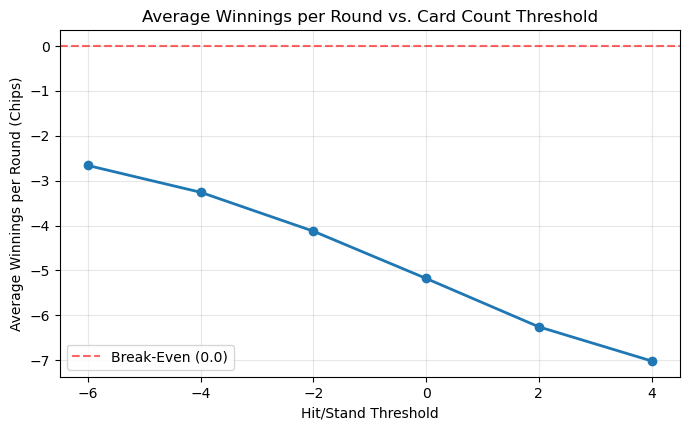

In [ ]:
# -6 was the best threshold tested because higher thresholds make the player hit too often and bust

thresholds = [-6, -4, -2, 0, 2, 4]
scan_results = {}

print('--Scanning Threshold Values (100 Games of 50 Rounds Each)--')
print(
    f"{'Threshold':>10} | {'Avg Final Chips':>15} | {'Avg/Round':>11} |"
    f" {'Std/Round':>10} | {'Win Prob':>9} | {'Loss Prob':>9}"
)
print('-' * 78)

for thresh in thresholds:
  random.seed(8)
  t_end_chips = []
  t_round_rates = []

  for _ in range(100):
    sp = AIPlayer(name='StrategyPlayer', chips=starting_chips, threshold=thresh)
    others = [
        Dealer(name='DealerPlayer 1', chips=starting_chips),
        Dealer(name='DealerPlayer 2', chips=starting_chips),
        Dealer(name='DealerPlayer 3', chips=starting_chips),
    ]
    g = BlackjackGame(
        players=[sp] + others,
        num_decks=6,
        verbose=False,
        show_suits=False,
        quiet=True,
    )
    for _ in range(50):
      if sp.chips <= 0:
        break
      g.play_round()

    t_end_chips.append(sp.chips)
    t_round_rates.append(sp.net_winnings / sp.hands_played)

  mean_chips = statistics.mean(t_end_chips)
  mean_rate = statistics.mean(t_round_rates)
  std_rate = statistics.stdev(t_round_rates)
  win_p = sum(1 for c in t_end_chips if c > starting_chips) / 100
  loss_p = sum(1 for c in t_end_chips if c < starting_chips) / 100

  scan_results[thresh] = mean_rate
  print(
      f'{thresh:>10} | {mean_chips:>15.2f} | {mean_rate:>+11.4f} |'
      f' {std_rate:>10.4f} | {win_p:>8.0%} | {loss_p:>8.0%}'
  )

best_threshold = max(scan_results, key=scan_results.get)
print(
    f'\nOptimal Threshold among tested values: {best_threshold} (Avg'
    f' {scan_results[best_threshold]:+.4f} chips/round)'
)

plt.figure(figsize=(8, 4.5))
plt.plot(
    list(scan_results.keys()),
    list(scan_results.values()),
    marker='o',
    linewidth=2,
)
plt.axhline(0, color='red', linestyle='--', alpha=0.6, label='Break-Even (0.0)')
plt.title('Average Winnings per Round vs. Card Count Threshold')
plt.xlabel('Hit/Stand Threshold')
plt.ylabel('Average Winnings per Round (Chips)')
plt.xticks(thresholds)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

10. Create a new strategy based on web searches or your own ideas. Demonstrate that the new strategy will result in increased or decreased winnings. 

--SmartCounter vs. Naive Step 6 Strategy (100 Games)--
Naive Strategy (threshold=-2) -> Avg Chips: 793.70 | Avg/Round: -4.1260 | Win Prob: 1%
SmartCounter Strategy         -> Avg Chips: 961.75 | Avg/Round: -0.7650 | Win Prob: 38%


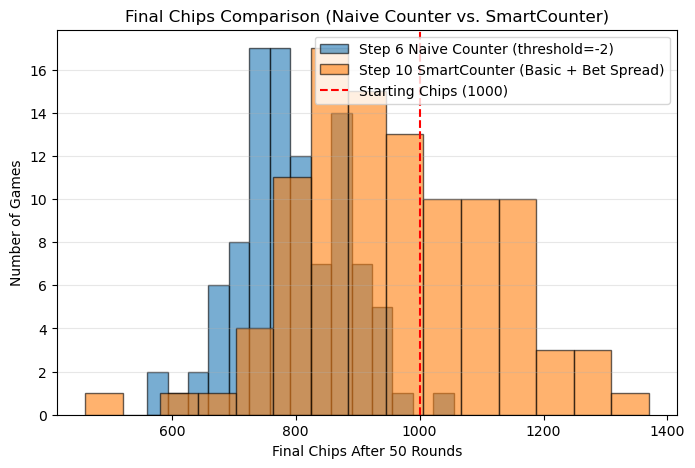

In [110]:
class SmartCounterPlayer(AIPlayer):

  def __init__(self, name='SmartCounter', chips=1000, threshold=2):
    super().__init__(name=name, chips=chips, threshold=threshold)

  # vary bet size based on the running count (bet bigger when deck has more 10s/Aces)
  def place_bet(self, seen_cards, amount=10):
    running_count = self.count_cards(seen_cards)
    if running_count >= 4:
      bet_amount = 40
    elif running_count >= 2:
      bet_amount = 20
    else:
      bet_amount = 10
    return super().place_bet(seen_cards, amount=bet_amount)

  # combine hand total, dealer upcard, and running count
  def decide_action(self, dealer_upcard, seen_cards):
    total = self.hand.get_total()
    upcard_val = dealer_upcard.get_value()
    running_count = self.count_cards(seen_cards)

    # never bust on 11 or less
    if total <= 11:
      return 'hit'
    # always stand on 17 or higher
    if total >= 17:
      return 'stand'

    # for stiff totals (12-16), check dealer's upcard and running count
    if 2 <= upcard_val <= 6:
      # dealer shows weak card (likely to bust): stand, unless 12 vs 2/3 with negative count
      if total == 12 and upcard_val in [2, 3] and running_count < 0:
        return 'hit'
      return 'stand'
    else:
      # dealer shows strong card (7-Ace): stand on 16 if count is high, otherwise hit
      if total == 16 and running_count >= self.threshold:
        return 'stand'
      return 'hit'


random.seed(8)
smart_end_chips = []
smart_round_rates = []

for _ in range(100):
  smart_p = SmartCounterPlayer(
      name='SmartCounter', chips=starting_chips, threshold=2
  )
  others = [
      Dealer(name='DealerPlayer 1', chips=starting_chips),
      Dealer(name='DealerPlayer 2', chips=starting_chips),
      Dealer(name='DealerPlayer 3', chips=starting_chips),
  ]
  g = BlackjackGame(
      players=[smart_p] + others,
      num_decks=6,
      verbose=False,
      show_suits=False,
      quiet=True,
  )
  for _ in range(50):
    if smart_p.chips <= 0:
      break
    g.play_round()

  smart_end_chips.append(smart_p.chips)
  smart_round_rates.append(smart_p.net_winnings / smart_p.hands_played)

smart_avg_chips = statistics.mean(smart_end_chips)
smart_avg_rate = statistics.mean(smart_round_rates)
smart_std_rate = statistics.stdev(smart_round_rates)
smart_win_prob = sum(1 for c in smart_end_chips if c > starting_chips) / 100
smart_loss_prob = sum(1 for c in smart_end_chips if c < starting_chips) / 100

print('--SmartCounter vs. Naive Step 6 Strategy (100 Games)--')
print(
    f'Naive Strategy (threshold=-2) -> Avg Chips: {avg_end_chips:.2f} |'
    f' Avg/Round: {avg_winnings_per_round:+.4f} | Win Prob: {prob_win:.0%}'
)
print(
    f'SmartCounter Strategy         -> Avg Chips: {smart_avg_chips:.2f} |'
    f' Avg/Round: {smart_avg_rate:+.4f} | Win Prob: {smart_win_prob:.0%}'
)

plt.figure(figsize=(8, 5))
plt.hist(
    end_chips_list,
    bins=15,
    alpha=0.6,
    edgecolor='black',
    label='Step 6 Naive Counter (threshold=-2)',
)
plt.hist(
    smart_end_chips,
    bins=15,
    alpha=0.6,
    edgecolor='black',
    label='Step 10 SmartCounter (Basic + Bet Spread)',
)
plt.axvline(
    starting_chips,
    color='red',
    linestyle='--',
    label=f'Starting Chips ({starting_chips})',
)
plt.title('Final Chips Comparison (Naive Counter vs. SmartCounter)')
plt.xlabel('Final Chips After 50 Rounds')
plt.ylabel('Number of Games')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()